<a href="https://colab.research.google.com/github/Arsh-rahman01/Ai-and-datascience/blob/master/Student_performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()   # choose StudentPerformanceFactors.csv
df = pd.read_csv("/content/StudentPerformanceFactors.csv")
df.head()

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors (1).csv


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:
print(df.shape)
print(df.info())
df.describe()

(6607, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [5]:
# Missing values
print(df.isnull().sum())

# Fill missing text columns with the most common value
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Remove duplicates
df = df.drop_duplicates()

# Exam score cannot be above 100
df["Exam_Score"] = df["Exam_Score"].clip(upper=100)

print("Missing after cleaning:", df.isnull().sum().sum())

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64
Missing after cleaning: 0


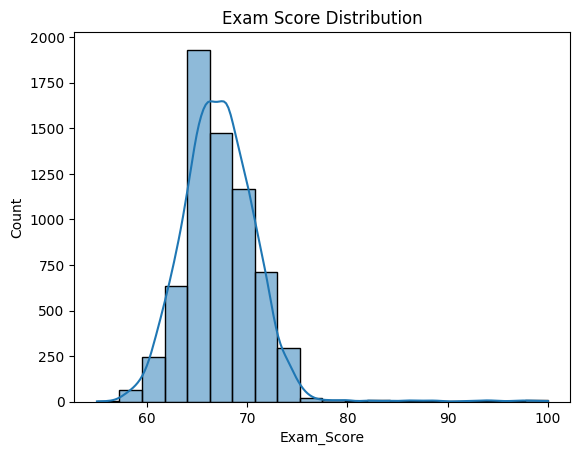

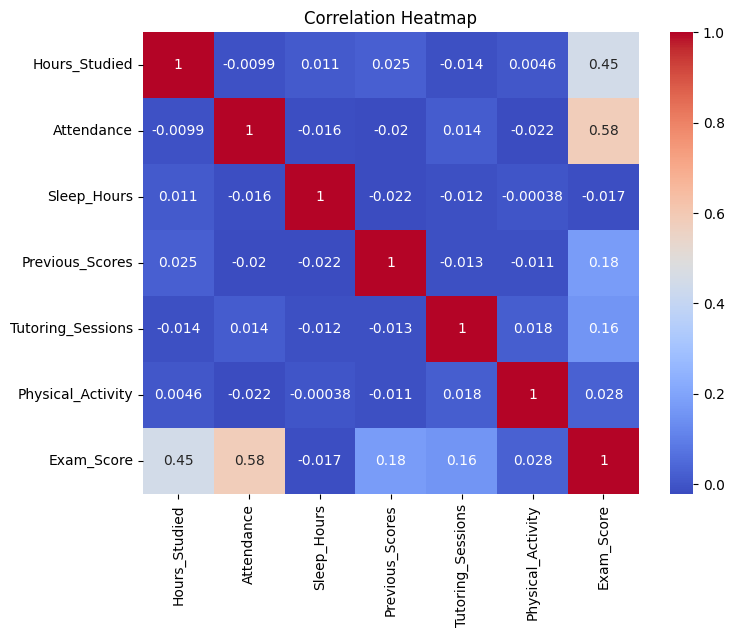

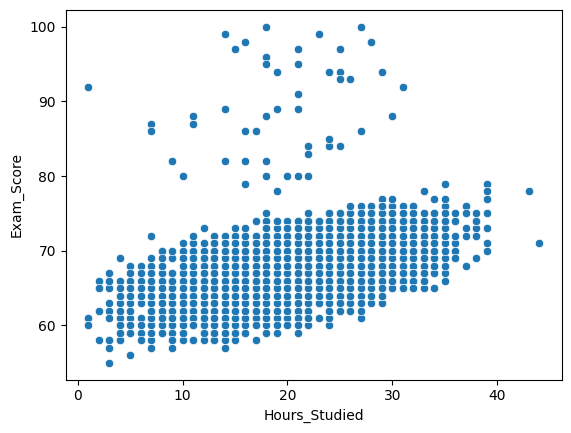

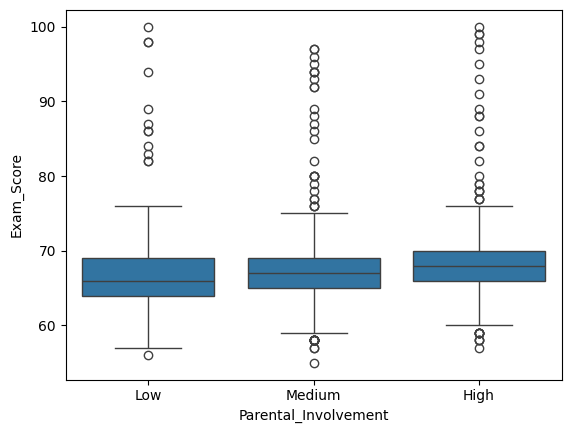

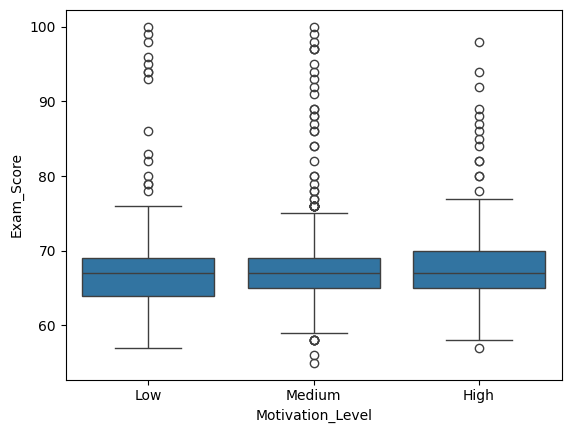

In [6]:
# Score distribution
sns.histplot(df["Exam_Score"], bins=20, kde=True)
plt.title("Exam Score Distribution")
plt.show()

# Correlation of numeric columns
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Hours studied vs score
sns.scatterplot(x="Hours_Studied", y="Exam_Score", data=df)
plt.show()

# Category vs score
sns.boxplot(x="Parental_Involvement", y="Exam_Score", data=df)
plt.show()

sns.boxplot(x="Motivation_Level", y="Exam_Score", data=df)
plt.show()

In [7]:
# New feature: study effort combined with attendance
df["Effort_Score"] = df["Hours_Studied"] * df["Attendance"] / 100

# Convert text columns to numbers (one-hot encoding)
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.shape

(6607, 29)

In [8]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop("Exam_Score", axis=1)
y = df_encoded["Exam_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(5285, 28) (1322, 28)


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append([
        name,
        r2_score(y_test, pred),
        mean_absolute_error(y_test, pred),
        np.sqrt(mean_squared_error(y_test, pred))
    ])

results_df = pd.DataFrame(results, columns=["Model", "R2", "MAE", "RMSE"])
results_df

,Model,R2,MAE,RMSE
0,Linear Regression,0.769939,0.453114,1.803312
1,Random Forest,0.653857,1.144266,2.211956


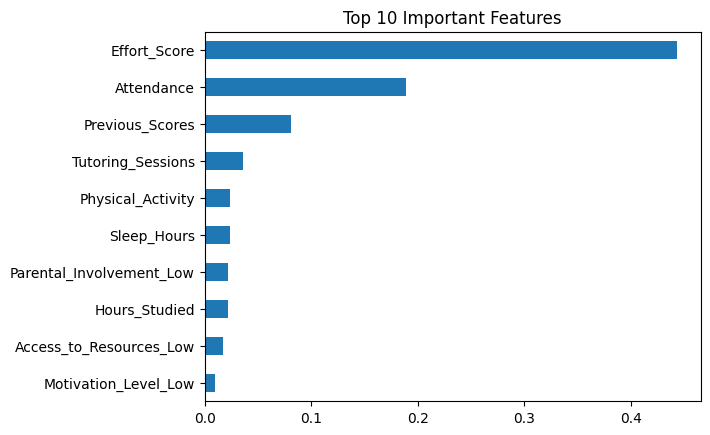

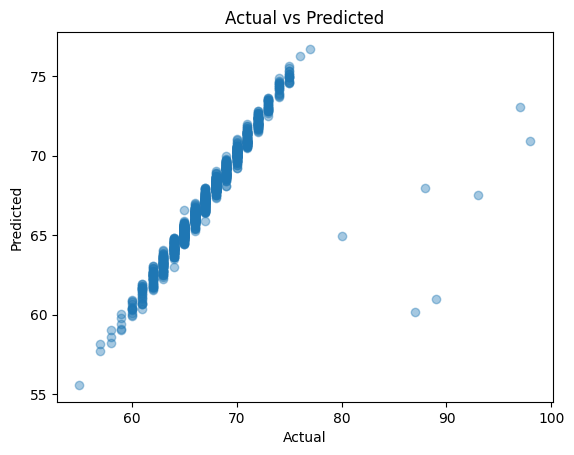

In [10]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns)
imp.nlargest(10).sort_values().plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()

# Predicted vs actual (using the best model)
best = models["Linear Regression"]
pred = best.predict(X_test)
plt.scatter(y_test, pred, alpha=0.4)
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()